# Informe econòmic de Catalunya

**Producció, població i situació socioeconòmica per comarques i àmbits territorials (1981–2023)**

Adaptació del *World Economic Report* de Maven Analytics amb dades oficials de l'[Idescat](https://www.idescat.cat).
Les dades s'han descarregat de l'API Taules v2 amb `python src/extract.py` (vegeu el README).

| Original (món) | Aquesta versió (Catalunya) |
|---|---|
| Països / regions del Banc Mundial | Comarques / 8 àmbits territorials |
| PIB, població | PIB territorial, estimacions de població |
| Esperança de vida vs. PIB per càpita | Renda per persona vs. PIB per habitant |
| HDI | Índex socioeconòmic territorial (IST) |
| Consum elèctric vs. PIB per càpita | Pes de la indústria al VAB vs. PIB per habitant |

In [1]:
# Imports
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.gridspec import GridSpec
import seaborn as sns

# Settings
pd.set_option("display.max_columns", None)
mpl.rcParams["font.family"] = "sans-serif"
mpl.rcParams["font.sans-serif"] = ["Lato", "Segoe UI", "DejaVu Sans"]
mpl.rcParams["axes.spines.top"] = False
mpl.rcParams["axes.spines.right"] = False

ROOT = Path.cwd().parent if Path.cwd().name == "python" else Path.cwd()
DATA = ROOT / "data" / "processed"
OUT = ROOT / "python" / "output"
OUT.mkdir(parents=True, exist_ok=True)

ANY = "2023"  # últim any amb PIB, renda i IST per comarca alhora


def fmt(x, dec=0):
    """Format numèric català: punt de milers i coma decimal."""
    s = f"{x:,.{dec}f}"
    return s.replace(",", "X").replace(".", ",").replace("X", ".")

## 1. Carregar i revisar les dades

In [2]:
def load(name):
    return pd.read_csv(DATA / f"{name}.csv", dtype={"geo_code": str, "period_code": str})

pib_at = load("pib_at")
pib_cat = load("pib_cat")
pib_com = load("pib_com")
vab_com = load("vab_com")
pob_com = load("poblacio_com")
ist_com = load("ist_com")
ind_com = load("ist_indicadors_com")
ambits = pd.read_csv(ROOT / "config" / "ambits_comarques.csv")
# PIB de Catalunya en volum (creixement real); opcional si encara no s'ha descarregat
pib_vol = load("pib_volum_cat") if (DATA / "pib_volum_cat.csv").exists() else None

pib_com.head()

,source,period_code,period_label,geo_code,geo_label,CONCEPT,CONCEPT_label,value,status
0,pib,2011,2011,01,Alt Camp,GDP_ME,PIB (milions €),1163.7,NaN
1,pib,2011,2011,01,Alt Camp,GDP_E_INH,PIB per habitant (€),25880.0,NaN
2,pib,2011,2011,01,Alt Camp,GPD_INH_CAT_100,PIB per habitant (índex Catalunya=100),93.3,NaN
3,pib,2011,2011,02,Alt Empordà,GDP_ME,PIB (milions €),2936.9,NaN
4,pib,2011,2011,02,Alt Empordà,GDP_E_INH,PIB per habitant (€),21188.0,NaN


In [3]:
# Tipus de dades i memòria
pib_com.info(memory_usage="deep")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1716 entries, 0 to 1715
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   source         1716 non-null   object 
 1   period_code    1716 non-null   object 
 2   period_label   1716 non-null   int64  
 3   geo_code       1716 non-null   object 
 4   geo_label      1716 non-null   object 
 5   CONCEPT        1716 non-null   object 
 6   CONCEPT_label  1716 non-null   object 
 7   value          1680 non-null   float64
 8   status         297 non-null    object 
dtypes: float64(1), int64(1), object(7)
memory usage: 726.6 KB


In [4]:
# Valors buits i codis d'estat per taula
# 'p' = dada provisional · '..' = dada no disponible (p. ex. comarques abans de crear-se)
taules = {"pib_com": pib_com, "vab_com": vab_com, "poblacio_com": pob_com, "ist_com": ist_com, "ist_indicadors_com": ind_com}
pd.DataFrame({
    nom: {"files": len(df), "% buits": round(df["value"].isna().mean() * 100, 1),
          **df["status"].value_counts().to_dict()}
    for nom, df in taules.items()
}).T.fillna(0)

,files,% buits,p,..,b
pib_com,1716.0,2.1,261.0,36.0,0.0
vab_com,2860.0,2.1,435.0,60.0,0.0
poblacio_com,3916.0,3.9,0.0,154.0,0.0
ist_com,440.0,2.0,44.0,9.0,0.0
ist_indicadors_com,2580.0,13.5,86.0,349.0,126.0


In [5]:
# Quines comarques tenen buits?
pob_com.loc[pob_com["value"].isna()].groupby("geo_label")["period_code"].agg(["min", "max", "count"])

,min,max,count
geo_label,,,
Lluçanès,1981S1,2023S1,85
Moianès,1981S1,2015S1,69


El Moianès (2015) i el Lluçanès (2023) són comarques noves: abans de crear-se no tenen dades pròpies i els seus municipis compten dins de les comarques d'origen. El Lluçanès encara no té renda ni IST per al 2023, així que queda fora dels gràfics comarcals.

## 2. Preparar les dades

In [6]:
# PIB per àmbit (milers de milions €, preus corrents). Fem servir l'àmbit oficial de l'API.
gdp_pivot = (pib_at.query("CONCEPT == 'GDP_ME' and geo_code != 'TOTAL'")
             .assign(year=lambda d: d["period_code"].astype(int))
             .pivot_table(index="year", columns="geo_label", values="value", aggfunc="sum") / 1_000)
gdp_pivot.tail()

geo_label,Alt Pirineu i Aran,Camp de Tarragona,Comarques Centrals,Comarques Gironines,Metropolità,Penedès,Ponent,Terres de l'Ebre
year,,,,,,,,
2019,1.9395,16.4077,11.4765,21.1264,175.4900,11.2019,10.7583,4.8985
2020,1.7246,13.6868,10.7417,19.0188,155.8644,10.1369,10.1005,4.2263
2021,1.8291,16.5031,11.5717,21.0694,167.0707,11.1584,11.0454,5.1955
2022,2.1463,18.4971,12.6840,23.6769,185.3676,12.3447,11.8253,5.7264
2023,2.2269,19.4441,13.9965,25.8535,202.7098,13.5858,12.7950,5.8651


In [7]:
# Població per àmbit (milions). Sumem comarques amb la correspondència de config/
# perquè la sèrie oficial per àmbits canvia de divisió territorial cap al 2012 (vegeu README).
pop_pivot = (pob_com.query("geo_code != 'TOTAL' and period_code.str.endswith('S1')")
             .merge(ambits, left_on="geo_label", right_on="comarca", how="left")
             .assign(year=lambda d: d["period_code"].str[:4].astype(int))
             .pivot_table(index="year", columns="ambit", values="value", aggfunc="sum") / 1_000_000)
pop_pivot.tail()

ambit,Alt Pirineu i Aran,Camp de Tarragona,Comarques Centrals,Comarques Gironines,Metropolità,Penedès,Ponent,Terres de l'Ebre
year,,,,,,,,
2021,0.074241,0.532484,0.412407,0.769322,4.915184,0.498692,0.366772,0.180794
2022,0.074630,0.536357,0.413607,0.774729,4.907655,0.504474,0.368082,0.182289
2023,0.075859,0.547800,0.419782,0.792661,4.993120,0.514037,0.373613,0.185091
2024,0.076543,0.555957,0.426215,0.804851,5.062386,0.522878,0.375964,0.187437
2025,0.077215,0.564162,0.431254,0.814218,5.134101,0.530997,0.381531,0.190648


In [8]:
# Taula comarcal de l'any d'anàlisi: una fila per comarca
def serie(df, concept, nom, sector=None):
    d = df.query("period_code == @ANY and CONCEPT == @concept and geo_code != 'TOTAL'")
    if sector:
        d = d.query("SEC_ACTIV_G == @sector")
    return d.set_index("geo_label")["value"].rename(nom)

comarques = pd.concat([
    serie(pib_com, "GDP_ME", "pib_meur"),
    serie(pib_com, "GDP_E_INH", "pib_hab"),
    serie(ind_com, "AVER_INC_EUR", "renda"),
    serie(ist_com, "IST_G_IND", "ist"),
    serie(vab_com, "GVA_M_EUR", "vab_ind", "B-E"),
    serie(vab_com, "GVA_M_EUR", "vab_total", "TOTAL"),
], axis=1).join(ambits.set_index("comarca")["ambit"])

# Com a l'original de Maven: població = PIB / PIB per habitant
comarques["poblacio_m"] = comarques["pib_meur"] / comarques["pib_hab"]
comarques["ind_pct"] = comarques["vab_ind"] / comarques["vab_total"] * 100
comarques = comarques.dropna(subset=["renda", "ist"])
comarques.sort_values("pib_hab", ascending=False).head()

,pib_meur,pib_hab,renda,ist,vab_ind,vab_total,ambit,poblacio_m,ind_pct
geo_label,,,,,,,,,
Ribera d'Ebre,1581.4,71546.0,14848.0,90.4,1028.1,1451.4,Terres de l'Ebre,0.022103,70.835056
Barcelonès,104496.5,44769.0,17745.0,101.4,6368.6,95909.7,Metropolità,2.334126,6.640204
Baix Llobregat,36120.0,42760.0,16878.0,104.1,9730.1,33151.9,Metropolità,0.844715,29.350052
Alt Camp,1937.3,41923.0,14883.0,95.2,936.4,1778.1,Camp de Tarragona,0.046211,52.662955
Segarra,928.2,41137.0,14499.0,85.8,527.0,851.9,Ponent,0.022564,61.861721


In [9]:
# IST per àmbit: mitjana de les comarques ponderada per població (Catalunya = 100)
ist_ambit = (comarques.groupby("ambit")
             .apply(lambda g: np.average(g["ist"], weights=g["poblacio_m"]), include_groups=False)
             .rename("ist").sort_values(ascending=False))
ist_ambit

ambit
Metropolità            102.311774
Penedès                 98.845120
Alt Pirineu i Aran      97.379197
Comarques Centrals      96.073643
Camp de Tarragona       95.537725
Comarques Gironines     90.496403
Ponent                  89.113133
Terres de l'Ebre        86.911268
Name: ist, dtype: float64

In [10]:
# Referències de Catalunya
pib_hab_cat = pib_cat.query("period_code == @ANY and CONCEPT == 'GDP_E_INH'")["value"].item()
renda_cat = np.average(comarques["renda"], weights=comarques["poblacio_m"])
pib_hab_cat, round(renda_cat)

(37259.0, 16465)

## 3. Gràfics individuals

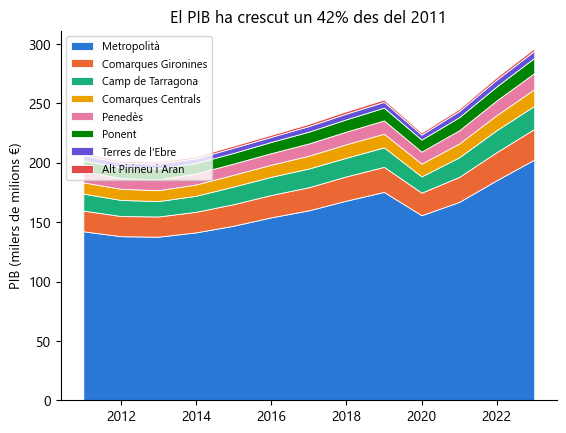

In [11]:
# Un color fix per àmbit (paleta categòrica validada per a daltonisme), ordenat pel PIB
ordre = gdp_pivot.iloc[-1].sort_values(ascending=False).index.tolist()
paleta = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
colors = dict(zip(ordre, paleta))

fig, ax = plt.subplots()
ax.stackplot(gdp_pivot.index, [gdp_pivot[a] for a in ordre], labels=ordre,
             colors=[colors[a] for a in ordre], edgecolor="white", linewidth=0.6)
ax.set_title("El PIB ha crescut un 42% des del 2011")
ax.set_ylabel("PIB (milers de milions €)")
ax.legend(loc="upper left", fontsize=8)
plt.show()

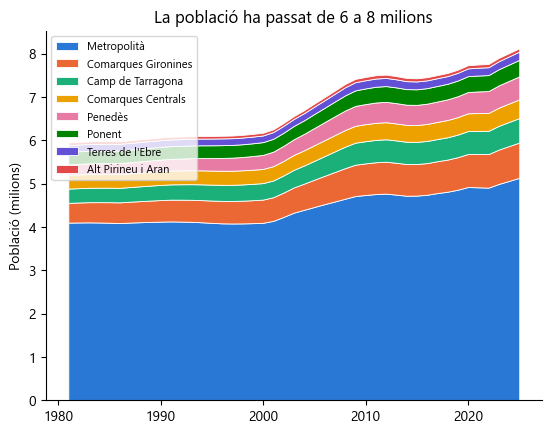

In [12]:
fig, ax = plt.subplots()
ax.stackplot(pop_pivot.index, [pop_pivot[a] for a in ordre], labels=ordre,
             colors=[colors[a] for a in ordre], edgecolor="white", linewidth=0.6)
ax.set_title("La població ha passat de 6 a 8 milions")
ax.set_ylabel("Població (milions)")
ax.legend(loc="upper left", fontsize=8)
plt.show()

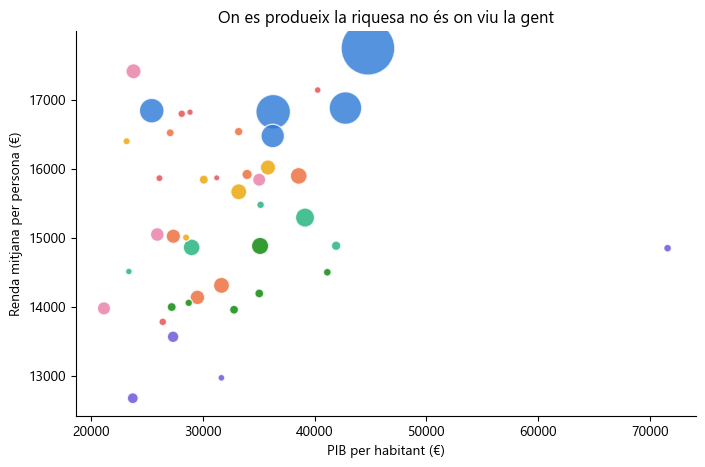

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=comarques, x="pib_hab", y="renda", size="poblacio_m", sizes=(20, 1500),
                hue="ambit", palette=colors, alpha=0.8, edgecolor="white", linewidth=1, legend=False, ax=ax)
ax.set(title="On es produeix la riquesa no és on viu la gent",
       xlabel="PIB per habitant (€)", ylabel="Renda mitjana per persona (€)")
plt.show()

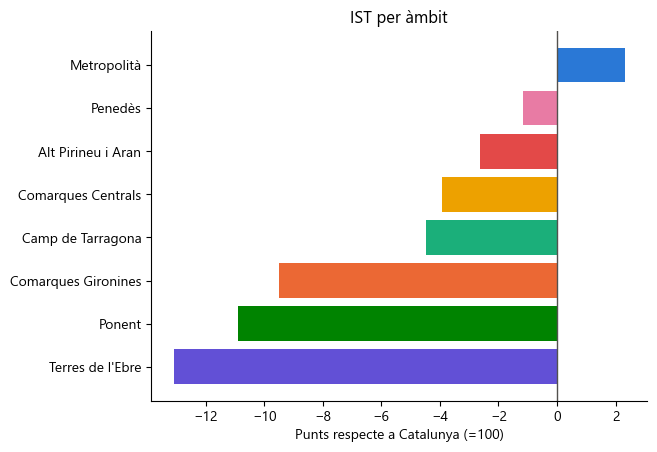

In [14]:
fig, ax = plt.subplots()
dif = ist_ambit - 100
ax.barh(dif.index[::-1], dif.values[::-1], color=[colors[a] for a in dif.index[::-1]])
ax.axvline(0, color="#52514e", linewidth=1)
ax.set(title="IST per àmbit", xlabel="Punts respecte a Catalunya (=100)")
plt.show()

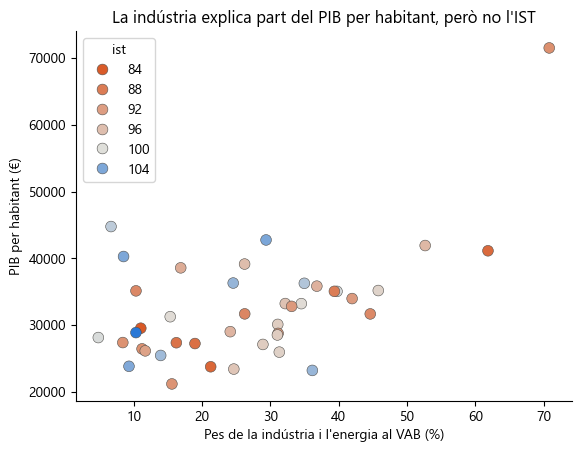

In [15]:
# Divergent centrat en 100 (Catalunya): taronja per sota, blau per sobre, gris al mig
ist_cmap = LinearSegmentedColormap.from_list("ist", ["#d95926", "#e0dfda", "#2a78d6"])
ist_norm = TwoSlopeNorm(vmin=comarques["ist"].min(), vcenter=100, vmax=comarques["ist"].max())

fig, ax = plt.subplots()
sns.scatterplot(data=comarques, x="ind_pct", y="pib_hab", hue="ist", hue_norm=ist_norm,
                palette=ist_cmap, edgecolor="#52514e", linewidth=0.4, s=60, ax=ax)
ax.set(title="La indústria explica part del PIB per habitant, però no l'IST",
       xlabel="Pes de la indústria i l'energia al VAB (%)", ylabel="PIB per habitant (€)")
plt.show()

## 4. Infografia final

In [16]:
# Xifres per als textos (es recalculen si s'actualitzen les dades)
creix_pib = (gdp_pivot.iloc[-1].sum() / gdp_pivot.iloc[0].sum() - 1) * 100
if pib_vol is not None:
    v = pib_vol.query("CONCEPT == 'GDP' and INDICATOR == 'VALUE'").set_index("period_code")["value"]
    creix_real = (v[str(gdp_pivot.index[-1])] / v[str(gdp_pivot.index[0])] - 1) * 100
    text_real = f"\n(un {fmt(creix_real)}% descomptant la inflació)."
else:
    text_real = "."
pes_metro_pib = gdp_pivot.iloc[-1]["Metropolità"] / gdp_pivot.iloc[-1].sum() * 100
pes_metro_pob = pop_pivot.loc[int(ANY), "Metropolità"] / pop_pivot.loc[int(ANY)].sum() * 100
creix_pob = (pop_pivot.iloc[-1] / pop_pivot.iloc[0] - 1) * 100
any_pob_ini, any_pob_fi = pop_pivot.index[0], pop_pivot.index[-1]

top_pib = comarques["pib_hab"].idxmax()
# Comarca "residencial": la que té més renda en relació amb el seu PIB per habitant
comarques["renda_vs_pib"] = comarques["renda"] / comarques["pib_hab"]
resid = comarques["renda_vs_pib"].idxmax()
rank_renda = int(comarques["renda"].rank(ascending=False)[resid])
# Posició en PIB per habitant entre totes les comarques amb dada (inclou el Lluçanès, que no té renda)
pib_hab_tots = serie(pib_com, "GDP_E_INH", "pib_hab")
rank_pib, n_pib = int(pib_hab_tots.rank(ascending=False)[resid]), int(pib_hab_tots.count())
sobre_mitjana = ist_ambit[ist_ambit > 100].index.tolist()
r = comarques[["pib_hab", "renda", "ist", "ind_pct"]].corr()
r_sense_top = comarques.drop(top_pib)[["pib_hab", "ist", "ind_pct"]].corr()  # sense el valor extrem

text_1 = f"""El PIB català ha crescut un {fmt(creix_pib)}% en
termes nominals entre {gdp_pivot.index[0]} i {gdp_pivot.index[-1]}{text_real}
L'àmbit Metropolità genera el {fmt(pes_metro_pib)}%
del PIB amb el {fmt(pes_metro_pob)}% de la població.

Des de {any_pob_ini}, el Penedès és l'àmbit
que més ha crescut en població
(+{fmt(creix_pob['Penedès'])}%), seguit de les
Comarques Gironines (+{fmt(creix_pob['Comarques Gironines'])}%)."""

text_2 = f"""El PIB es comptabilitza on es produeix;
la renda, on viu la gent.

La Ribera d'Ebre té el PIB per habitant
més alt ({fmt(comarques.loc[top_pib, 'pib_hab'])} €) per la central
nuclear d'Ascó, però una renda
de {fmt(comarques.loc[top_pib, 'renda'])} €.

En canvi, el {resid} és la {rank_renda}a comarca
en renda ({fmt(comarques.loc[resid, 'renda'])} €) però la {rank_pib}a de {n_pib}
en PIB per habitant ({fmt(comarques.loc[resid, 'pib_hab'])} €):
una part dels residents treballa
i genera PIB fora de la comarca."""

text_3 = f"""L'IST resumeix ocupació, estudis,
qualificació, origen i renda.
Àmbits per sobre de la mitjana:
{', '.join(sobre_mitjana) or 'cap'}.

Entre comarques, el PIB per habitant
no té relació amb l'IST (r = {fmt(r.loc['pib_hab', 'ist'], 2)})
ni amb la renda (r = {fmt(r.loc['pib_hab', 'renda'], 2)}).
El pes de la indústria hi té una
relació moderada (r = {fmt(r.loc['ind_pct', 'pib_hab'], 2)}; {fmt(r_sense_top.loc['ind_pct', 'pib_hab'], 2)}
sense la {top_pib})."""

print(text_1, text_2, text_3, sep="\n\n---\n\n")

El PIB català ha crescut un 42% en
termes nominals entre 2011 i 2023
(un 19% descomptant la inflació).
L'àmbit Metropolità genera el 68%
del PIB amb el 63% de la població.

Des de 1981, el Penedès és l'àmbit
que més ha crescut en població
(+120%), seguit de les
Comarques Gironines (+78%).

---

El PIB es comptabilitza on es produeix;
la renda, on viu la gent.

La Ribera d'Ebre té el PIB per habitant
més alt (71.546 €) per la central
nuclear d'Ascó, però una renda
de 14.848 €.

En canvi, el Garraf és la 2a comarca
en renda (17.411 €) però la 39a de 43
en PIB per habitant (23.819 €):
una part dels residents treballa
i genera PIB fora de la comarca.

---

L'IST resumeix ocupació, estudis,
qualificació, origen i renda.
Àmbits per sobre de la mitjana:
Metropolità.

Entre comarques, el PIB per habitant
no té relació amb l'IST (r = 0,01)
ni amb la renda (r = 0,16).
El pes de la indústria hi té una
relació moderada (r = 0,54; 0,34
sense la Ribera d'Ebre).


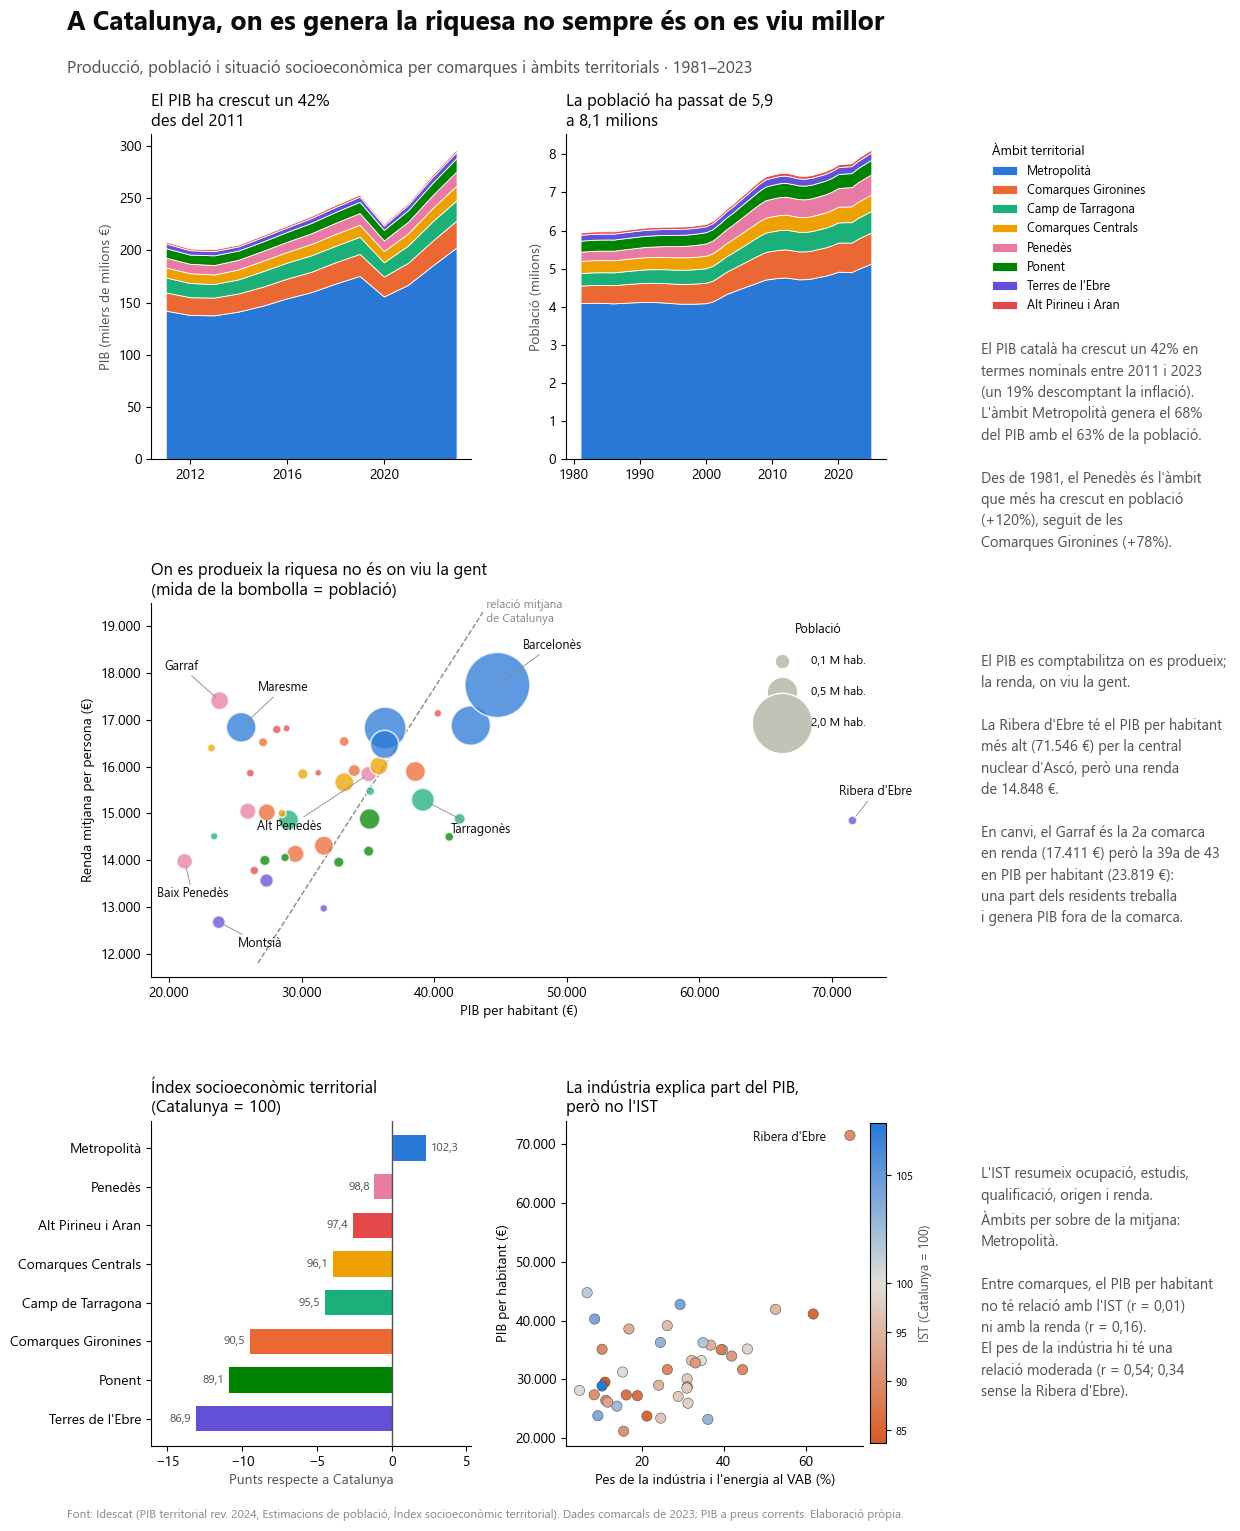

In [17]:
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"

fig = plt.figure(figsize=(13, 16), facecolor="white")
gs = GridSpec(nrows=3, ncols=3, figure=fig, width_ratios=[1, 1, 0.78],
              height_ratios=[1, 1.15, 1], wspace=0.32, hspace=0.42,
              left=0.135, right=0.965, top=0.89, bottom=0.07)

fig.text(0.07, 0.955, "A Catalunya, on es genera la riquesa no sempre és on es viu millor",
         fontsize=19, fontweight="bold", color=INK)
fig.text(0.07, 0.928, f"Producció, població i situació socioeconòmica per comarques i àmbits territorials · {any_pob_ini}–{ANY}",
         fontsize=12, color=INK2)

def text_box(ax, txt):
    ax.axis("off")
    ax.text(0, 0.5, txt, fontsize=10.5, color=INK2, va="center", linespacing=1.45)

## Eix 1: PIB per àmbit ##
ax1 = fig.add_subplot(gs[0, 0])
ax1.stackplot(gdp_pivot.index, [gdp_pivot[a] for a in ordre], colors=[colors[a] for a in ordre],
              edgecolor="white", linewidth=0.6)
ax1.set_title(f"El PIB ha crescut un {fmt(creix_pib)}%\ndes del {gdp_pivot.index[0]}", fontsize=12, loc="left")
ax1.set_ylabel("PIB (milers de milions €)", color=INK2)
ax1.xaxis.set_major_locator(mticker.MultipleLocator(4))

## Eix 2: població per àmbit ##
ax2 = fig.add_subplot(gs[0, 1])
ax2.stackplot(pop_pivot.index, [pop_pivot[a] for a in ordre], labels=ordre,
              colors=[colors[a] for a in ordre], edgecolor="white", linewidth=0.6)
ax2.set_title(f"La població ha passat de {fmt(pop_pivot.iloc[0].sum(), 1)}\na {fmt(pop_pivot.iloc[-1].sum(), 1)} milions", fontsize=12, loc="left")
ax2.set_ylabel("Població (milions)", color=INK2)

ax_t1 = fig.add_subplot(gs[0, 2])
ax_t1.axis("off")
ax_t1.legend(*ax2.get_legend_handles_labels(), loc="upper left", fontsize=9, frameon=False,
             title="Àmbit territorial", title_fontsize=9.5, alignment="left")
ax_t1.text(0, 0.36, text_1, fontsize=10.5, color=INK2, va="top", linespacing=1.45)

## Eix 3: bombolles PIB per habitant vs renda ##
ax3 = fig.add_subplot(gs[1, 0:2])
sns.scatterplot(data=comarques, x="pib_hab", y="renda", size="poblacio_m", sizes=(25, 2200),
                hue="ambit", palette=colors, alpha=0.75, edgecolor="white", linewidth=1.2,
                legend=False, ax=ax3)
ax3.set_ylim(11_500, 19_500)
ratio_cat = renda_cat / pib_hab_cat
xs = np.linspace(11_800 / ratio_cat, 19_300 / ratio_cat, 50)
ax3.plot(xs, xs * ratio_cat, color=MUTED, linestyle="--", linewidth=1, zorder=0)
ax3.text(xs[-1], xs[-1] * ratio_cat, " relació mitjana\n de Catalunya", fontsize=8.5, color=MUTED, va="center")
# Etiquetes selectives (offset en punts, línia guia fina)
for com, dx, dy in [("Ribera d'Ebre", -10, 18), ("Barcelonès", 18, 26), ("Tarragonès", 20, -24),
                    ("Garraf", -40, 22), ("Maresme", 12, 26), ("Baix Penedès", -20, -26),
                    ("Alt Penedès", -80, -40), ("Montsià", 14, -18)]:
    if com in comarques.index:
        ax3.annotate(com, (comarques.loc[com, "pib_hab"], comarques.loc[com, "renda"]),
                     xytext=(dx, dy), textcoords="offset points", fontsize=9, color=INK,
                     arrowprops=dict(arrowstyle="-", color=MUTED, linewidth=0.6, shrinkA=0, shrinkB=4))
# Llegenda de mides (població)
for pob_m in (0.1, 0.5, 2.0):
    ax3.scatter([], [], s=25 + (pob_m - comarques["poblacio_m"].min()) /
                (comarques["poblacio_m"].max() - comarques["poblacio_m"].min()) * (2200 - 25),
                color="#c3c2b7", edgecolor="white", label=f"{fmt(pob_m, 1)} M hab.")
ax3.legend(title="Població", loc="upper right", frameon=False, fontsize=8.5, title_fontsize=9,
           labelspacing=1.6, borderpad=1.2, handletextpad=1.5)
ax3.set_title("On es produeix la riquesa no és on viu la gent\n(mida de la bombolla = població)",
              fontsize=12, loc="left")
ax3.set(xlabel="PIB per habitant (€)", ylabel="Renda mitjana per persona (€)")
for a in (ax3.xaxis, ax3.yaxis):
    a.set_major_formatter(mticker.FuncFormatter(lambda v, _: fmt(v)))

text_box(fig.add_subplot(gs[1, 2]), text_2)

## Eix 4: IST per àmbit ##
ax4 = fig.add_subplot(gs[2, 0])
dif = (ist_ambit - 100).sort_values()
ax4.barh(dif.index, dif.values, color=[colors[a] for a in dif.index], height=0.65)
ax4.axvline(0, color=INK2, linewidth=1)
for y, v in enumerate(dif.values):
    ax4.text(v + (0.3 if v >= 0 else -0.3), y, fmt(v + 100, 1), va="center",
             ha="left" if v >= 0 else "right", fontsize=8.5, color=INK2)
ax4.set_title("Índex socioeconòmic territorial\n(Catalunya = 100)", fontsize=12, loc="left")
ax4.set_xlabel("Punts respecte a Catalunya", color=INK2)
ax4.set_xlim(dif.min() - 3, max(dif.max(), 0) + 3)

## Eix 5: indústria vs PIB per habitant ##
ax5 = fig.add_subplot(gs[2, 1])
sns.scatterplot(data=comarques, x="ind_pct", y="pib_hab", hue="ist", hue_norm=ist_norm,
                palette=ist_cmap, edgecolor=INK2, linewidth=0.4, s=55, legend=False, ax=ax5)
ax5.set_title("La indústria explica part del PIB,\nperò no l'IST", fontsize=12, loc="left")
ax5.set(xlabel="Pes de la indústria i l'energia al VAB (%)", ylabel="PIB per habitant (€)")
ax5.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: fmt(v)))
ax5.annotate(top_pib, (comarques.loc[top_pib, "ind_pct"], comarques.loc[top_pib, "pib_hab"]),
             xytext=(-70, -4), textcoords="offset points", fontsize=9, color=INK)
cb = fig.colorbar(mpl.cm.ScalarMappable(norm=ist_norm, cmap=ist_cmap), ax=ax5, fraction=0.05, pad=0.02)
cb.set_label("IST (Catalunya = 100)", fontsize=9, color=INK2)
cb.ax.tick_params(labelsize=8)

text_box(fig.add_subplot(gs[2, 2]), text_3)

fig.text(0.07, 0.025,
         "Font: Idescat (PIB territorial rev. 2024, Estimacions de població, Índex socioeconòmic territorial). "
         f"Dades comarcals de {ANY}; PIB a preus corrents. Elaboració pròpia.",
         fontsize=8.5, color=MUTED)

fig.savefig(OUT / "informe_economic_catalunya.png", dpi=150)
fig.savefig(OUT / "informe_economic_catalunya.pdf")
plt.show()

## 5. Pregunta final

**Quina és la correlació entre el PIB per habitant i l'IST per comarca el 2023?**

A l'original, la correlació entre PIB per càpita i HDI entre països és molt alta. A Catalunya, entre comarques, passa el contrari:

In [18]:
comarques[["pib_hab", "renda", "ist", "ind_pct"]].corr().round(2)

,pib_hab,renda,ist,ind_pct
pib_hab,1.00,0.16,0.01,0.54
renda,0.16,1.00,0.85,-0.22
ist,0.01,0.85,1.00,-0.17
ind_pct,0.54,-0.22,-0.17,1.00


In [19]:
# Spearman (per rangs): menys sensible a valors extrems com la Ribera d'Ebre
comarques[["pib_hab", "renda", "ist"]].corr(method="spearman").round(2)

,pib_hab,renda,ist
pib_hab,1.00,0.24,0.09
renda,0.24,1.00,0.86
ist,0.09,0.86,1.00


In [20]:
# Robustesa 1: sense la comarca amb el PIB per habitant més alt (valor extrem)
comarques.drop(top_pib)[["pib_hab", "renda", "ist", "ind_pct"]].corr().round(2)

,pib_hab,renda,ist,ind_pct
pib_hab,1.00,0.30,0.15,0.34
renda,0.30,1.00,0.85,-0.21
ist,0.15,0.85,1.00,-0.13
ind_pct,0.34,-0.21,-0.13,1.00


In [21]:
# Robustesa 2: PIB per habitant amb cadascun dels components de l'IST (cap no hi té relació)
components = (ind_com.query("period_code == @ANY and geo_code != 'TOTAL'")
              .pivot_table(index="geo_label", columns="CONCEPT_label", values="value"))
components.join(comarques["pib_hab"], how="inner").corr()["pib_hab"].drop("pib_hab").round(2)

població amb estudis baixos (%)                               0.10
població estrangera de països de renda baixa o mitjana (%)    0.20
població jove sense estudis postobligatoris (%)              -0.03
població ocupada (%)                                          0.01
renda mitjana per persona (€)                                 0.16
treballadors de baixa qualificació (%)                       -0.17
Name: pib_hab, dtype: float64

**Conclusió:** el PIB per habitant comarcal reflecteix *on* hi ha l'activitat productiva (indústria, energia, serveis centrals), no la situació socioeconòmica dels residents: no té relació amb l'IST ni amb els seus components d'ocupació, estudis i qualificació, i amb la renda la relació és feble. La correlació alta entre la renda i l'IST (r = 0,85) és en part mecànica, perquè la renda és un dels components de l'IST, i no s'ha de llegir com una relació independent. Amb 42 comarques, una sola comarca extrema com la Ribera d'Ebre pesa molt: per això també es mostren la correlació per rangs (Spearman) i la correlació sense aquesta comarca.

*Font de les dades: Idescat. Les dades no s'han modificat.*